# 02 – Preprocessing (Note Sequences for LSTM)
**Project**: [MIDI Music Generation](https://github.com/S33mi/midi-music-generation)  
**Author**: [S33mi](https://github.com/S33mi/)  

Convert MAESTRO piano MIDI files into fixed-length note sequences  
suitable for next-step prediction with an LSTM.

Output (saved under `data/processed/`):
- `train_notes.npy` / `val_notes.npy` – arrays of shape `(n_seq, seq_len, 3)`  
  features: `[pitch, step, duration]`
- `vocab_size` and other config in `preprocess_config.pkl`

## 1. Setup & Imports

In [1]:
# !pip install pretty_midi

In [2]:
import os
import glob
import pathlib
import collections
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pretty_midi
import tensorflow as tf
from tqdm.auto import tqdm
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Download / Locate MAESTRO (same as notebook 01)


In [3]:
DATA_DIR = pathlib.Path("data/maestro-v2.0.0")
ZIP_NAME = "maestro-v2.0.0-midi.zip"
URL = "https://storage.googleapis.com/magentadata/datasets/maestro/v2.0.0/maestro-v2.0.0-midi.zip"

if not DATA_DIR.exists():
    print("Downloading MAESTRO MIDI (~56 MB) ...")
    tf.keras.utils.get_file(
        ZIP_NAME,
        origin=URL,
        extract=True,
        cache_dir=".",
        cache_subdir="data",
    )
else:
    print(f"Using existing data at {DATA_DIR}")

filenames = sorted(glob.glob(str(DATA_DIR / "**" / "*.mid*"), recursive=True))
print(f"MIDI files: {len(filenames)}")

MIDI files: 0


In [4]:
DATA_DIR = pathlib.Path("data/maestro-v2.0.0")
ZIP_NAME = "maestro-v2.0.0-midi.zip"
URL = "https://storage.googleapis.com/magentadata/datasets/maestro/v2.0.0/maestro-v2.0.0-midi.zip"

# Clean previous broken attempts
if DATA_DIR.exists():
    shutil.rmtree(DATA_DIR)
if pathlib.Path("data").exists():
    # also remove the cached zip if present
    zip_path = pathlib.Path("data") / ZIP_NAME
    if zip_path.exists():
        zip_path.unlink()

print("Downloading MAESTRO MIDI (~56 MB) ...")
tf.keras.utils.get_file(
    fname=ZIP_NAME,
    origin=URL,
    extract=True,
    cache_dir=".",
    cache_subdir="data",
)
print("Download + extract done.")

# Check where files landed
print("\nAfter extract – contents of data/:")
!ls -la data/

# The zip usually extracts to data/maestro-v2.0.0/
# but sometimes the year folders end up directly under data/
if not DATA_DIR.exists():
    # Try the alternative structure
    possible = list(pathlib.Path("data").glob("**/2004"))
    if possible:
        print("Found year folders under:", possible[0].parent)
        DATA_DIR = possible[0].parent
    else:
        print("Still cannot locate maestro folder. Paste the output of the diagnostic cell above.")


# List MIDI files
filenames = sorted(glob.glob(str(DATA_DIR / "**" / "*.mid*"), recursive=True))
print(f"\nNumber of MIDI files: {len(filenames)}")
print("Example paths:")
for p in filenames[:5]:
    print(" ", p)

59243107/59243107 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Download + extract done.

After extract – contents of data/:
total 57872
drwxr-xr-x 4 root root     4096 Oct 26 08:40 .
drwxr-xr-x 1 root root     4096 Oct 26 08:17 ..
-rw-r--r-- 1 root root 59243107 Oct 26 08:40 maestro-v2.0.0-midi.zip
drwxr-xr-x 3 root root     4096 Oct 26 08:17 maestro-v2_extracted
drwxr-xr-x 2 root root     4096 Oct 26 08:30 processed
Found year folders under: data/maestro-v2_extracted/maestro-v2.0.0

Number of MIDI files: 1282
Example paths:
  data/maestro-v2_extracted/maestro-v2.0.0/2004/MIDI-Unprocessed_SMF_02_R1_2004_01-05_ORIG_MID--AUDIO_02_R1_2004_05_Track05_wav.midi
  data/maestro-v2_extracted/maestro-v2.0.0/2004/MIDI-Unprocessed_SMF_02_R1_2004_01-05_ORIG_MID--AUDIO_02_R1_2004_06_Track06_wav.midi
  data/maestro-v2_extracted/maestro-v2.0.0/2004/MIDI-Unprocessed_SMF_02_R1_2004_01-05_ORIG_MID--AUDIO_02_R1_2004_08_Track08_wav.midi
  data/maestro-v2_extracted/maestro-v2.0.0/2004/MIDI-Unprocessed_SMF_02_R1_2004_01

## 3. Extract Notes from a MIDI File

In [5]:
def midi_to_notes(midi_file: str) -> pd.DataFrame:
    """Extract pitch, start, end, step, duration from first non-drum instrument."""
    try:
        pm = pretty_midi.PrettyMIDI(midi_file)
    except Exception:
        return pd.DataFrame()

    instrument = None
    for inst in pm.instruments:
        if not inst.is_drum and len(inst.notes) > 0:
            instrument = inst
            break
    if instrument is None:
        return pd.DataFrame()

    notes = collections.defaultdict(list)
    sorted_notes = sorted(instrument.notes, key=lambda n: n.start)
    prev_start = sorted_notes[0].start

    for note in sorted_notes:
        start = note.start
        end = note.end
        notes["pitch"].append(note.pitch)
        notes["start"].append(start)
        notes["end"].append(end)
        notes["step"].append(start - prev_start)
        notes["duration"].append(end - start)
        notes["velocity"].append(note.velocity)
        prev_start = start

    return pd.DataFrame(notes)

# Quick check
sample = midi_to_notes(filenames[0])
print(f"Sample notes: {len(sample)}")
display(sample.head())

Sample notes: 7894


,pitch,start,end,step,duration,velocity
0,71,1.092708,1.189583,0.000000,0.096875,60
1,55,1.279167,1.496875,0.186458,0.217708,44
2,71,1.288542,1.793750,0.009375,0.505208,54
3,59,1.463542,1.631250,0.175000,0.167708,55
4,62,1.633333,1.753125,0.169792,0.119792,52


## 4. Hyperparameters for Sequences

In [6]:
SEQ_LENGTH = 32          # notes per input window
# We predict the *next* note → each training example is
# input: notes[i : i+SEQ_LENGTH], target: notes[i+SEQ_LENGTH]

MIN_NOTES_PER_FILE = SEQ_LENGTH + 10   # skip very short pieces
MAX_FILES = None         # set e.g. 200 for a quick Colab run; None = all

# Feature order we will use
FEATURE_NAMES = ["pitch", "step", "duration"]
N_FEATURES = len(FEATURE_NAMES)

print(f"Sequence length : {SEQ_LENGTH}")
print(f"Features        : {FEATURE_NAMES}")

Sequence length : 32
Features        : ['pitch', 'step', 'duration']


## 5. Build Note Arrays from Many Files

In [7]:
def extract_all_notes(file_list, max_files=None, min_notes=MIN_NOTES_PER_FILE):
    """Return a list of DataFrames (one per usable MIDI file)."""
    if max_files is not None:
        file_list = file_list[:max_files]

    note_dfs = []
    skipped = 0
    for f in tqdm(file_list, desc="Extracting notes"):
        df = midi_to_notes(f)
        if len(df) < min_notes:
            skipped += 1
            continue
        # Clean extreme outliers (helps training stability)
        df = df[(df["step"] >= 0) & (df["step"] < 2.0)]
        df = df[(df["duration"] > 0) & (df["duration"] < 4.0)]
        df = df[(df["pitch"] >= 21) & (df["pitch"] <= 108)]  # piano range
        if len(df) < min_notes:
            skipped += 1
            continue
        note_dfs.append(df.reset_index(drop=True))

    print(f"Usable files: {len(note_dfs)} | Skipped: {skipped}")
    return note_dfs

note_dfs = extract_all_notes(filenames, max_files=MAX_FILES)
total_notes = sum(len(d) for d in note_dfs)
print(f"Total notes collected: {total_notes}")

Extracting notes:   0%|          | 0/1282 [00:00<?, ?it/s]

Usable files: 1282 | Skipped: 0
Total notes collected: 7105041


## 6. Create Sliding Windows → (X, y)


In [8]:
def create_sequences(note_dfs, seq_length=SEQ_LENGTH):
    """
    From a list of note DataFrames, create:
      X: (n_sequences, seq_length, n_features)
      y: (n_sequences, n_features)   # the next note after each window
    Features = [pitch, step, duration]
    """
    xs, ys = [], []
    for df in tqdm(note_dfs, desc="Building sequences"):
        arr = df[FEATURE_NAMES].values.astype(np.float32)
        n = len(arr)
        if n <= seq_length:
            continue
        for i in range(n - seq_length):
            xs.append(arr[i : i + seq_length])
            ys.append(arr[i + seq_length])
    X = np.stack(xs, axis=0)
    y = np.stack(ys, axis=0)
    return X, y

X, y = create_sequences(note_dfs, SEQ_LENGTH)
print(f"X shape: {X.shape}")   # (n_seq, SEQ_LENGTH, 3)
print(f"y shape: {y.shape}")   # (n_seq, 3)

Building sequences:   0%|          | 0/1282 [00:00<?, ?it/s]

X shape: (7064017, 32, 3)
y shape: (7064017, 3)


## 7. Normalize step & duration (pitch stays as integer for now)

In [9]:
# Pitch: keep raw MIDI number (0–127); model will embed or treat as regression
# Step & duration: scale to roughly [0, 1] using training statistics

step_mean, step_std = float(X[:, :, 1].mean()), float(X[:, :, 1].std() + 1e-8)
dur_mean, dur_std   = float(X[:, :, 2].mean()), float(X[:, :, 2].std() + 1e-8)

print(f"step  mean={step_mean:.4f}  std={step_std:.4f}")
print(f"dur   mean={dur_mean:.4f}  std={dur_std:.4f}")

def normalize_features(arr, step_mean, step_std, dur_mean, dur_std):
    out = arr.copy()
    out[..., 1] = (out[..., 1] - step_mean) / step_std
    out[..., 2] = (out[..., 2] - dur_mean) / dur_std
    return out

X_norm = normalize_features(X, step_mean, step_std, dur_mean, dur_std)
y_norm = normalize_features(y, step_mean, step_std, dur_mean, dur_std)

step  mean=0.0949  std=0.1494
dur   mean=0.1912  std=0.3102


## 8. Train / Validation Split

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_norm, y_norm, test_size=0.15, random_state=42, shuffle=True
)

print(f"Train: X={X_train.shape}  y={y_train.shape}")
print(f"Val  : X={X_val.shape}  y={y_val.shape}")

Train: X=(6004414, 32, 3)  y=(6004414, 3)
Val  : X=(1059603, 32, 3)  y=(1059603, 3)


## 9. Quick Sanity Plots

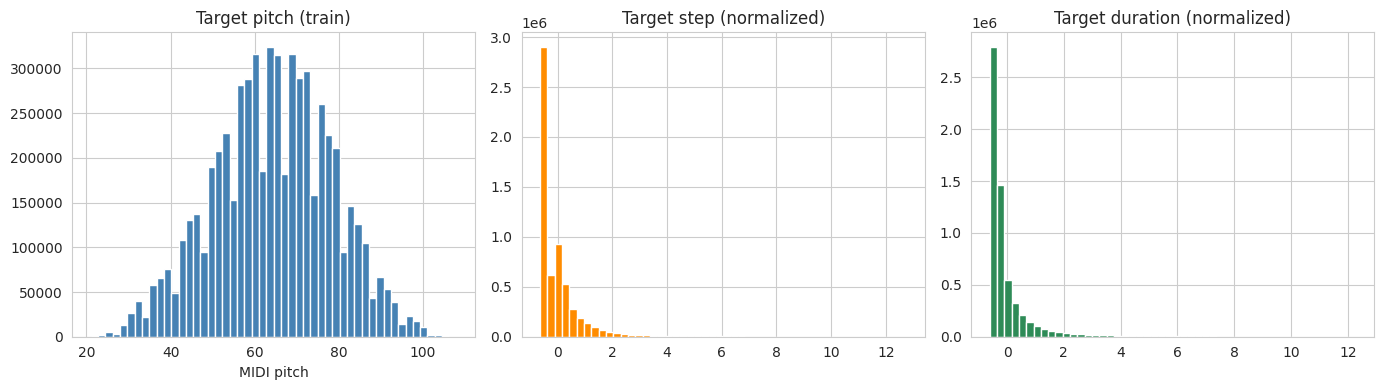

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(y_train[:, 0], bins=50, color="steelblue")
axes[0].set_title("Target pitch (train)")
axes[0].set_xlabel("MIDI pitch")

axes[1].hist(y_train[:, 1], bins=50, color="darkorange")
axes[1].set_title("Target step (normalized)")

axes[2].hist(y_train[:, 2], bins=50, color="seagreen")
axes[2].set_title("Target duration (normalized)")

plt.tight_layout()
plt.show()

## 10. Save Artifacts

In [12]:
os.makedirs("data/processed", exist_ok=True)

np.save("data/processed/X_train.npy", X_train)
np.save("data/processed/y_train.npy", y_train)
np.save("data/processed/X_val.npy", X_val)
np.save("data/processed/y_val.npy", y_val)

config = {
    "seq_length": SEQ_LENGTH,
    "feature_names": FEATURE_NAMES,
    "step_mean": step_mean,
    "step_std": step_std,
    "dur_mean": dur_mean,
    "dur_std": dur_std,
    "n_train": len(X_train),
    "n_val": len(X_val),
    "pitch_min": 21,
    "pitch_max": 108,
}

with open("data/processed/preprocess_config.pkl", "wb") as f:
    pickle.dump(config, f)

print("Saved:")
print("  data/processed/X_train.npy")
print("  data/processed/y_train.npy")
print("  data/processed/X_val.npy")
print("  data/processed/y_val.npy")
print("  data/processed/preprocess_config.pkl")
print("\nConfig:", config)

Saved:
  data/processed/X_train.npy
  data/processed/y_train.npy
  data/processed/X_val.npy
  data/processed/y_val.npy
  data/processed/preprocess_config.pkl

Config: {'seq_length': 32, 'feature_names': ['pitch', 'step', 'duration'], 'step_mean': 0.09490258991718292, 'step_std': 0.14939366281032562, 'dur_mean': 0.1912021040916443, 'dur_std': 0.31023889780044556, 'n_train': 6004414, 'n_val': 1059603, 'pitch_min': 21, 'pitch_max': 108}


## 11. Summary

| Item | Value |
|------|--------|
| Sequence length | 32 notes |
| Features per note | pitch, step, duration |
| Train sequences | Train: X=(6004414, 32, 3)  y=(6004414, 3) |
| Val sequences | Val  : X=(1059603, 32, 3)  y=(1059603, 3)  |
| Normalization | step & duration z-scored; pitch left as MIDI number |

**Next notebook**: `03_train_lstm.ipynb`  
→ Build a small LSTM that predicts the next `(pitch, step, duration)`.

---

**For contribution and insihght:** [S33mi](https://github.com/S33mi/)

Open to Data Science/Analytics and ML/ SI (fka AI) related opportunities